# 06 · McNemar + cluster bootstrap + charts + summary
Cost: $0.

In [1]:
import sys, json, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from dotenv import load_dotenv; load_dotenv(ROOT / '.env')
import nest_asyncio; nest_asyncio.apply()
import asyncio

In [2]:
import pt_report as R, pt_score as SC
names = ['base', 'harness_rubric', 'frontier', 'sft', 'sft_safety', 'sft_router']
systems = {n: SC.load_results(n) for n in names if SC.load_results(n)}
summary = R.compare_all(systems)
R.write_summary(summary)
print(R.charts(summary))
for mod in ('text', 'image', 'all'):
    print(f'\n### {mod}\n' + R.markdown_table(summary, mod))

['/Users/kush/pawtriage/results/charts/mcnemar.png', '/Users/kush/pawtriage/results/charts/bootstrap.png']

### text
| system | urgency acc | under-triage | harmful advice | top-1 cond | plan recall | $/1k chats | p95 ms | McNemar p | bootstrap 95% CI (pp) | real gain |
|---|---|---|---|---|---|---|---|---|---|---|
| base | 55.5% | 31.7% | 0.0% | 67.8% | 60.1% | $0.330 | 2339 | — | — | — |
| harness_rubric | 90.0% | 5.8% | 0.0% | 90.2% | 89.9% | $1.019 | 3344 | 1.3e-28 | +34.5 [+22.8, +49.2] | yes |
| sft | 77.2% | 25.4% | 0.0% | 72.8% | 66.1% | $1.814 | 2386 | 1.7e-12 | +21.8 [+1.8, +40.0] | yes |
| sft_safety | 82.5% | 16.7% | 0.0% | 72.8% | 67.7% | $1.814 | 2386 | 8.4e-21 | +27.0 [+16.8, +41.0] | yes |

### image
| system | urgency acc | under-triage | harmful advice | top-1 cond | plan recall | $/1k chats | p95 ms | McNemar p | bootstrap 95% CI (pp) | real gain |
|---|---|---|---|---|---|---|---|---|---|---|
| base | 26.3% | — | 0.0% | 16.7% | 29.3% | $0.330 | 2339 | — | — | — |
| 

In [3]:
print('REAL GAINS (p<0.05 AND CI excludes 0):')
for n, e in summary.items():
    for mod, res in e['vs_base'].items():
        for f, v in res.items():
            if isinstance(v, dict) and v.get('real_gain'):
                print(f'  {n} · {mod} · {f}: {v["bootstrap"]["mean_gap"]*100:+.1f}pp, p={v["mcnemar"]["p_exact"]:.2g}')
if 'video' in next(iter(summary.values()))['metrics']:
    print('video (n small, no significance claim):', {n: e['metrics']['video'] for n, e in summary.items()})

REAL GAINS (p<0.05 AND CI excludes 0):
  harness_rubric · text · urgency_correct: +34.5pp, p=1.3e-28
  harness_rubric · text · cond_top1_hit: +22.5pp, p=1e-15
  harness_rubric · image · urgency_correct: +48.4pp, p=3.2e-36
  harness_rubric · image · cond_top1_hit: +40.1pp, p=1e-29
  harness_rubric · image · image_finding_correct: +30.8pp, p=6.4e-21
  harness_rubric · all · urgency_correct: +40.6pp, p=3.7e-63
  harness_rubric · all · cond_top1_hit: +30.2pp, p=1e-42
  sft · text · urgency_correct: +21.8pp, p=1.7e-12
  sft · image · urgency_correct: +66.7pp, p=2.6e-61
  sft · image · cond_top1_hit: +63.8pp, p=1.3e-58
  sft · image · image_finding_correct: +51.6pp, p=1e-37
  sft · all · urgency_correct: +41.4pp, p=7.2e-61
  sft · all · cond_top1_hit: +30.8pp, p=3.9e-32
  sft_safety · text · urgency_correct: +27.0pp, p=8.4e-21
  sft_safety · image · urgency_correct: +66.7pp, p=2.6e-61
  sft_safety · image · cond_top1_hit: +63.8pp, p=1.3e-58
  sft_safety · image · image_finding_correct: +51.6

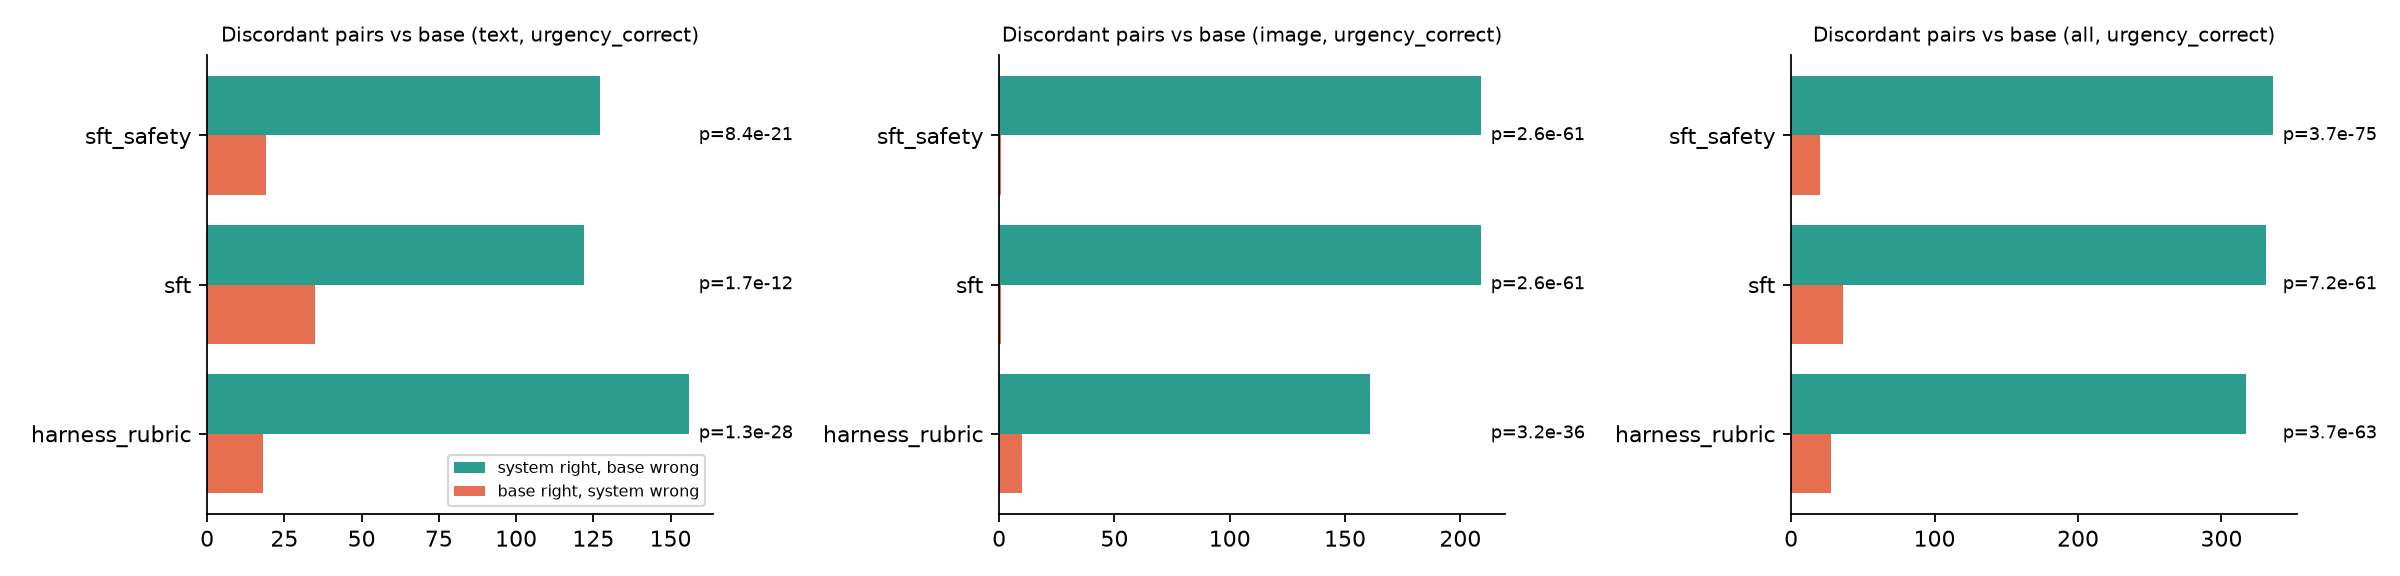

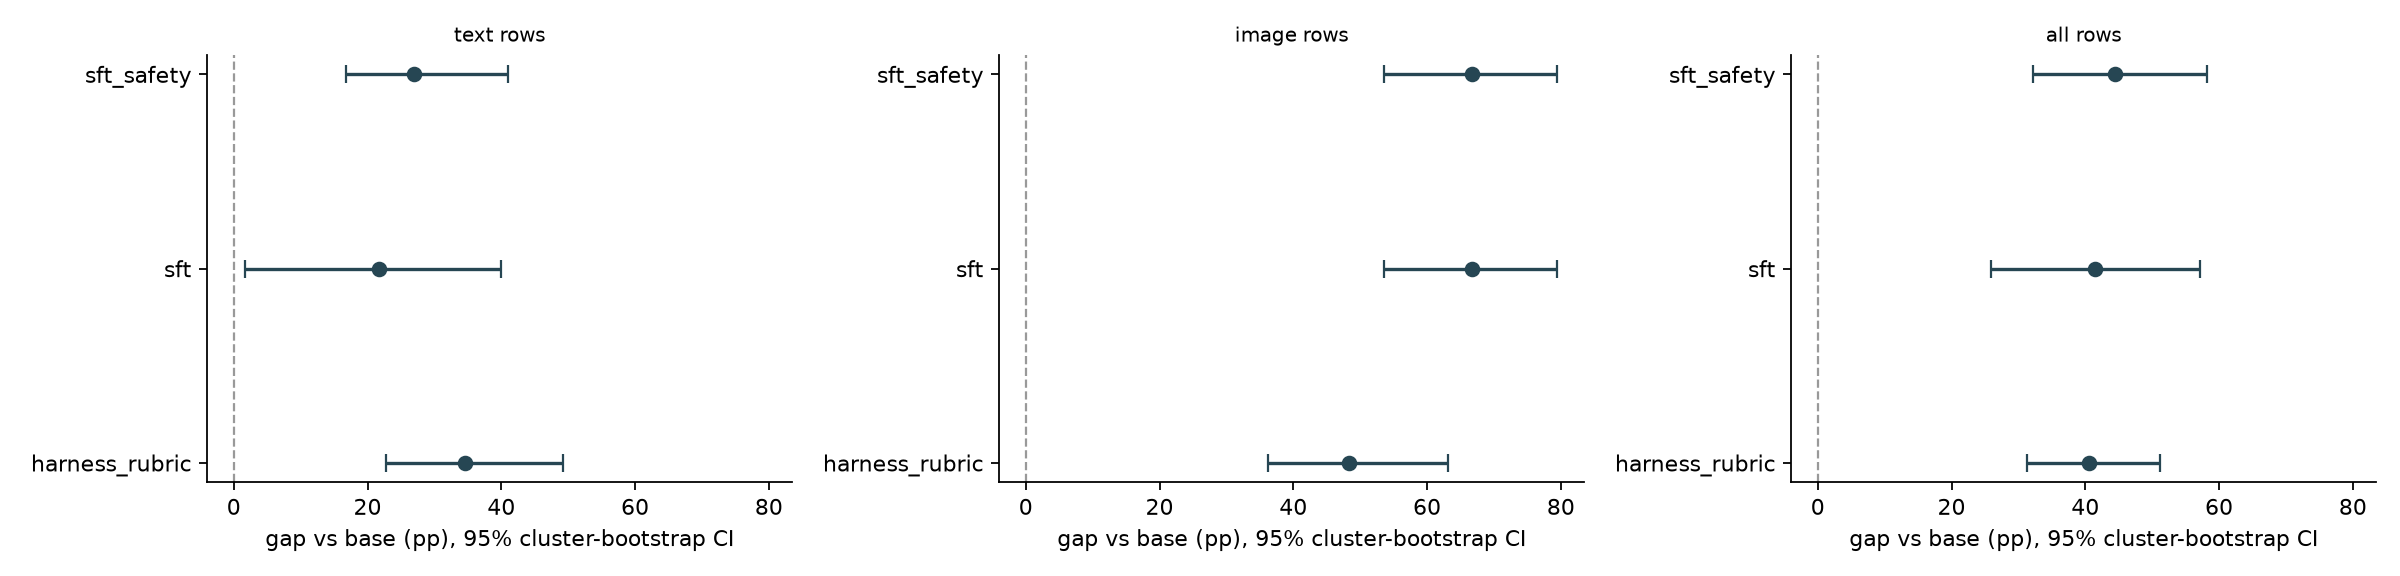

In [4]:
from IPython.display import Image, display
display(Image(str(ROOT/'results/charts/mcnemar.png'))); display(Image(str(ROOT/'results/charts/bootstrap.png')))